# Práctica de Campo N.º 5 — Notebook complementario
## Modelo no supervisado: agrupamiento de reportes ciudadanos con K-Means

**Curso:** Sistemas Inteligentes y Machine Learning — UPN
**Docente:** Dr. Víctor Jaime Polo Romero
**Integrantes:** Azcarate Noriega, Miguel Alonso · Candiotti Arancibia, Renzo · Del Portal Quevedo de la Cruz, Augusto · Arteaga Sánchez, Heyner Jhonel

---

### Supervisado frente a no supervisado

En el notebook principal el algoritmo aprendió de ejemplos **ya etiquetados**: se le dijo a qué categoría pertenecía cada uno de los 400 reportes de entrenamiento, y él buscó qué patrones las separaban.

Aquí se hace lo contrario: se le **ocultan las etiquetas**. El algoritmo recibe los 500 reportes sin saber a qué categoría pertenece ninguno, y debe encontrar por su cuenta grupos de reportes que se parezcan entre sí.

### Para qué sirve esto en el proyecto

1. **Validar la taxonomía.** Si los grupos que el algoritmo descubre por su cuenta coinciden con las seis categorías que el equipo definió a mano, esa taxonomía tiene sustento en los datos y no solo en el criterio de los integrantes.
2. **Detectar categorías faltantes.** Un grupo claro que no corresponda a ninguna de las seis indicaría que falta un área de servicio en la taxonomía.
3. **Abaratar el etiquetado.** Etiquetar a mano es la restricción más cara declarada en la PC2. Agrupar primero y revisar por grupo es más rápido que reporte por reporte.

### Aviso sobre la estructura de este notebook

El primer intento de agrupamiento **falla**, y el notebook lo documenta en lugar de esconderlo. Entender por qué falló es lo que lleva a la solución correcta, y ese diagnóstico es la parte más útil del ejercicio.

---
## 1. Preparación y carga

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import unicodedata, re, os
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RUTA = "reportes_ciudadanos_trujillo_2026.csv"
if not os.path.exists(RUTA):
    from google.colab import files
    subidos = files.upload(); RUTA = list(subidos.keys())[0]

df = pd.read_csv(RUTA)
print(f"Reportes cargados: {len(df)}")

Reportes cargados: 500


In [2]:
STOPWORDS_ES = set("""
a al algo algunas algunos ante antes como con contra cual cuando de del desde donde dos el
ella ellas ellos en entre era eran eres es esa esas ese eso esos esta estaba estado estamos
estan estar estas este esto estos estoy fue fueron ha habia han hasta hay la las le les lo los
mas me mi mientras mucho muy nada ni no nos nosotros o os otra otro para pero poco por porque
que quien se ser si sin sobre solo son su sus tambien tanto te tiene tienen todo todos tu tus
un una uno unos usted ustedes ya yo aqui ahi alli asi
""".split())

def normalizar(texto, extra=frozenset()):
    """Minusculas, sin tildes, sin signos, sin palabras vacias."""
    texto = str(texto).lower()
    texto = "".join(ch for ch in unicodedata.normalize("NFD", texto)
                    if unicodedata.category(ch) != "Mn")
    texto = re.sub(r"[^a-zñ\s]", " ", texto)
    return " ".join(p for p in texto.split()
                    if p not in STOPWORDS_ES and p not in extra and len(p) > 2)

df["texto_limpio"] = df.texto_reporte.apply(normalizar)
print(df[["texto_reporte", "texto_limpio"]].head(3).to_string(max_colwidth=70))

                                                           texto_reporte                                                           texto_limpio
0  BUEN DIA, EL SARDINEL DE URB. SANTA MARIA ESTÁ DESCASCARADO, ES MÁ...  buen dia sardinel urb santa maria descascarado tema presentacion v...
1  quiero reportar que las veredas de Monserrate estan hundidas en va...  quiero reportar veredas monserrate hundidas varios tramos parece t...
2                                      hay un problema serio en Rio Seco                                                problema serio rio seco


---
## 2. Primer intento — y por qué falla

Se vectoriza igual que en el notebook principal y se piden seis grupos.

Nota metodológica: aquí **sí** se vectoriza el corpus completo. No hay fuga de datos porque no hay conjunto de prueba ni predicción: el agrupamiento es un análisis descriptivo de los 500 reportes, no un modelo que después vaya a clasificar reportes nuevos.

In [3]:
vec_1 = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.6, sublinear_tf=True)
X_1 = vec_1.fit_transform(df.texto_limpio)
terminos_1 = vec_1.get_feature_names_out()

km_1 = KMeans(n_clusters=6, random_state=SEMILLA, n_init=20)
grupos_1 = km_1.fit_predict(X_1)

centros_1 = km_1.cluster_centers_.argsort()[:, ::-1]
print("TERMINOS CARACTERISTICOS DE CADA GRUPO — PRIMER INTENTO\n" + "=" * 72)
for g in range(6):
    palabras = ", ".join(terminos_1[i] for i in centros_1[g, :8])
    print(f"\nGrupo {g} ({(grupos_1 == g).sum()} reportes)\n   {palabras}")

ari_1 = adjusted_rand_score(df.categoria, grupos_1)
cruce_1 = pd.crosstab(grupos_1, df.categoria)
pureza_1 = np.mean([100 * cruce_1.loc[g].max() / cruce_1.loc[g].sum() for g in range(6)])
print(f"\n{'=' * 72}")
print(f"Indice Rand ajustado: {ari_1:.3f}   |   Pureza media: {pureza_1:.0f}%")

TERMINOS CARACTERISTICOS DE CADA GRUPO — PRIMER INTENTO

Grupo 0 (38 reportes)
   veces, varias veces, varias, reclamamos varias, reclamamos, reportamos varias, reportamos, libre

Grupo 1 (76 reportes)
   zona, zona reportamos, vecinos zona, vecinos, reportamos, agua, gracias, buenas

Grupo 2 (36 reportes)
   vez, vez manden, ojala, manden alguien, manden, ojala vez, alguien, vez mismo

Grupo 3 (233 reportes)
   dias, urb, hace, lleva, hace dias, puede, vereda, lleva dias

Grupo 4 (38 reportes)
   nadie, ver, viene ver, viene, nadie viene, atiende, nadie atiende, vengan ver

Grupo 5 (79 reportes)
   favor, atiendan, atiendan favor, favor atiendan, parque, dias, urb, larco

Indice Rand ajustado: 0.014   |   Pureza media: 26%


### Diagnóstico

Los grupos no hablan de baches ni de postes. Hablan de **fórmulas de cortesía y de queja**: *nadie viene a ver*, *por favor atiendan*, *ojalá esta vez manden a alguien*, *ya reclamamos varias veces*. También aparecen nombres de calles y urbanizaciones.

El algoritmo hizo exactamente lo que se le pidió: agrupar textos parecidos. Lo que pasa es que en estos reportes lo más repetido no es el problema denunciado sino **la forma de denunciarlo**. Un vecino molesto por un bache y otro molesto por la basura escriben el mismo cierre, y esa coincidencia pesa más que la diferencia de tema.

El índice Rand ajustado cercano a cero lo confirma: la coincidencia con la taxonomía del equipo es prácticamente la que daría el azar.

**Dos correcciones:**

1. **Stopwords de dominio.** Además de las palabras vacías del español, se eliminan las fórmulas de cortesía, las expresiones de queja y los nombres propios de lugares. No describen el problema, solo el tono del reclamo y su ubicación.
2. **Reducción de dimensionalidad con LSA.** TF-IDF deja cada reporte en un espacio de cientos de dimensiones donde las distancias pierden sentido (es lo que se conoce como *maldición de la dimensionalidad*). TruncatedSVD comprime ese espacio a unas pocas dimensiones que concentran los temas dominantes. Aplicado a texto, este procedimiento se llama **Análisis de Semántica Latente (LSA)**.

---
## 3. Segundo intento — con stopwords de dominio y LSA

In [4]:
# Formulas de cortesia, expresiones de queja y referencias geograficas.
# No describen el problema reportado, solo el tono del reclamo y su ubicacion.
STOPWORDS_DOMINIO = set("""
buenos buenas dias tardes dia favor xfa señores muni municipalidad municipio denuncio quiero
reportar alguien puede ver colmo otra vez reitero reclamo reclamamos veces varias vecinos zona
reportamos nadie viene atiendan atiende gracias cuando espero respuesta vecindario canso lleva
van hace desde ojala manden sabemos acudir urge solucion pa tmb sta nomas todavia conviene bien
mismo vengan sigue igual pesimo estado serio problema
""".split())

LUGARES = set("""
espana pizarro america mansiche larco husares junin palermo san andres quintanas primavera
recreo santa maria fatima monserrate covicorti buenos aires california vista alegre golf
liberacion social huerta grande condorcanqui manuel arevalo wichanzao veronica pueblo libre
jerusalen pumacahua rio seco miguel grau nuevo porvenir alto mochica marzo villa hermosa
victor tropico huanchaquito mar moche huacas delicias laredo trujillo barraza menocucho
salaverry balneario sector comite cuadra ovalo urb mercado plaza carretera campina puerto
principal centro
""".split())

EXTRA = STOPWORDS_DOMINIO | LUGARES
df["texto_tema"] = df.texto_reporte.apply(lambda t: normalizar(t, EXTRA))

print("Efecto de la limpieza adicional:\n")
for texto in df.texto_reporte.head(3):
    print("ORIGINAL   :", texto[:105])
    print("SOLO TEMA  :", normalizar(texto, EXTRA))
    print("-" * 100)

Efecto de la limpieza adicional:

ORIGINAL   : BUEN DIA, EL SARDINEL DE URB. SANTA MARIA ESTÁ DESCASCARADO, ES MÁS TEMA DE PRESENTACION EL VECINDARIO YA
SOLO TEMA  : buen sardinel descascarado tema presentacion ademas senal nombre calle torcida
----------------------------------------------------------------------------------------------------
ORIGINAL   : quiero reportar que las veredas de Monserrate estan hundidas en varios tramos, parece trocha
SOLO TEMA  : veredas hundidas varios tramos parece trocha
----------------------------------------------------------------------------------------------------
ORIGINAL   : hay un problema serio en Rio Seco
SOLO TEMA  : 
----------------------------------------------------------------------------------------------------


In [5]:
vec = TfidfVectorizer(ngram_range=(1, 1), min_df=2, max_df=0.5, sublinear_tf=True)
X = vec.fit_transform(df.texto_tema)
terminos = vec.get_feature_names_out()

print(f"Vocabulario tematico: {X.shape[1]} terminos "
      f"(antes eran {X_1.shape[1]} con las formulas de cortesia dentro)")

Vocabulario tematico: 370 terminos (antes eran 821 con las formulas de cortesia dentro)


### 3.1. ¿Cuántas dimensiones conservar en la LSA?

Se prueban varios tamaños y se elige por el **coeficiente de silueta**, que mide qué tan separados quedan los grupos: cada reporte se compara con su propio grupo y con el grupo vecino más cercano. Va de −1 a 1; más alto es mejor.

En texto los valores de silueta son bajos por naturaleza, porque los vectores viven en un espacio muy disperso donde casi todo está lejos de casi todo. Lo que importa es cuál configuración es *relativamente* mejor, no si el número parece alto.

In [6]:
filas = []
for n_dim in [10, 15, 20, 25, 30, 40, 60]:
    reductor = make_pipeline(TruncatedSVD(n_dim, random_state=SEMILLA),
                             Normalizer(copy=False))
    M = reductor.fit_transform(X)
    km = KMeans(n_clusters=6, random_state=SEMILLA, n_init=25)
    g = km.fit_predict(M)
    cr = pd.crosstab(g, df.categoria)
    filas.append({
        "Dimensiones LSA": n_dim,
        "Silueta": round(silhouette_score(M, g), 3),
        "ARI": round(adjusted_rand_score(df.categoria, g), 3),
        "Pureza media (%)": round(np.mean([100 * cr.loc[i].max() / cr.loc[i].sum()
                                           for i in range(6)]), 1),
    })

tabla_dim = pd.DataFrame(filas)
print(tabla_dim.to_string(index=False))

N_DIM = int(tabla_dim.loc[tabla_dim.Silueta.idxmax(), "Dimensiones LSA"])
print(f"\nSe elige {N_DIM} dimensiones (mejor silueta).")

 Dimensiones LSA  Silueta   ARI  Pureza media (%)
              10    0.284 0.300              63.7
              15    0.204 0.197              63.5
              20    0.157 0.194              67.7
              25    0.133 0.168              70.4
              30    0.114 0.289              73.9
              40    0.095 0.177              60.5
              60    0.077 0.206              72.1

Se elige 10 dimensiones (mejor silueta).


In [7]:
reductor = make_pipeline(TruncatedSVD(N_DIM, random_state=SEMILLA), Normalizer(copy=False))
M = reductor.fit_transform(X)

kmeans = KMeans(n_clusters=6, random_state=SEMILLA, n_init=25)
df["grupo"] = kmeans.fit_predict(M)

silueta = silhouette_score(M, df.grupo)
ari = adjusted_rand_score(df.categoria, df.grupo)
varianza = reductor.named_steps["truncatedsvd"].explained_variance_ratio_.sum()

print(f"Varianza retenida por la LSA : {100*varianza:.1f}%")
print(f"Coeficiente de silueta       : {silueta:.3f}   (primer intento: {silhouette_score(X_1, grupos_1):.3f})")
print(f"Indice Rand ajustado         : {ari:.3f}   (primer intento: {ari_1:.3f})")
print(f"\nTamaño de cada grupo:")
print(df.grupo.value_counts().sort_index().to_string())

Varianza retenida por la LSA : 16.6%
Coeficiente de silueta       : 0.284   (primer intento: 0.022)
Indice Rand ajustado         : 0.300   (primer intento: 0.014)

Tamaño de cada grupo:
grupo
0     53
1     65
2     64
3     86
4     58
5    174


### 3.2. ¿De qué habla ahora cada grupo?

Para nombrar los grupos se toman los términos más frecuentes de los reportes que cayeron en cada uno. (Con LSA de por medio, los centros del K-Means viven en el espacio comprimido y ya no se traducen directamente a palabras, así que se miran los textos.)

In [8]:
print("TERMINOS MAS FRECUENTES POR GRUPO — SEGUNDO INTENTO\n" + "=" * 72)
for g in range(6):
    sub = df[df.grupo == g]
    palabras = Counter(" ".join(sub.texto_tema).split()).most_common(10)
    print(f"\nGrupo {g} ({len(sub)} reportes)")
    print("   " + ", ".join(f"{p}" for p, _ in palabras))

TERMINOS MAS FRECUENTES POR GRUPO — SEGUNDO INTENTO

Grupo 0 (53 reportes)
   parque, pasto, caminar, quedo, bancas, despintadas, lleno, falta, pintar, rejas

Grupo 1 (65 reportes)
   semaforo, senal, carros, peatonal, pasan, falta, quedo, colegio, cruce, corren

Grupo 2 (64 reportes)
   basura, esquina, bolsas, acumula, noche, perros, quedo, desmonte, abren, ademas

Grupo 3 (86 reportes)
   pista, llueve, colegio, toda, varios, bache, chicos, vuelve, puro, lodo

Grupo 4 (58 reportes)
   vereda, caminan, ancianos, asilo, acera, juntas, abiertas, corren, senores, ademas

Grupo 5 (174 reportes)
   agua, poste, tapa, buzon, conexion, desague, quedo, cable, buen, urgente


In [9]:
for g in range(6):
    print(f"--- GRUPO {g} " + "-" * 82)
    for texto in df[df.grupo == g].texto_reporte.head(3):
        print("   ", texto[:112])
    print()

--- GRUPO 0 ----------------------------------------------------------------------------------
    la luminaria del parque de Jerusalen está quemada, ya se llevaron un celular ahi
    alguien puede ver que quedo el buzon de la av. Condorcanqui sin tapa, es un foco infeccioso ya reclamamos varias
    reitero mi reclamo, el tacho del parque de la av. Larco esta lleno atiendan por favor

--- GRUPO 1 ----------------------------------------------------------------------------------
    por favor hay una zanja abierta y sin señalizar en el balneario, los carros lo esquivan de golpe y casi chocan y
    por favor se abrio un hueco profundo en Covicorti, ya se cayeron dos motos está semana el vecindario ya se canso
    buen dia, la luz de urb. San Andres prende un poco tarde espero respuesta...

--- GRUPO 2 ----------------------------------------------------------------------------------
    las juntas de la acera de Rio Seco estan abiertas, conviene atenderlo antes que crezca y ademas se acu

---
## 4. ¿Coinciden los grupos con la taxonomía del equipo?

Esta es la pregunta central del análisis. Se cruzan los grupos descubiertos sin supervisión contra las categorías etiquetadas a mano.

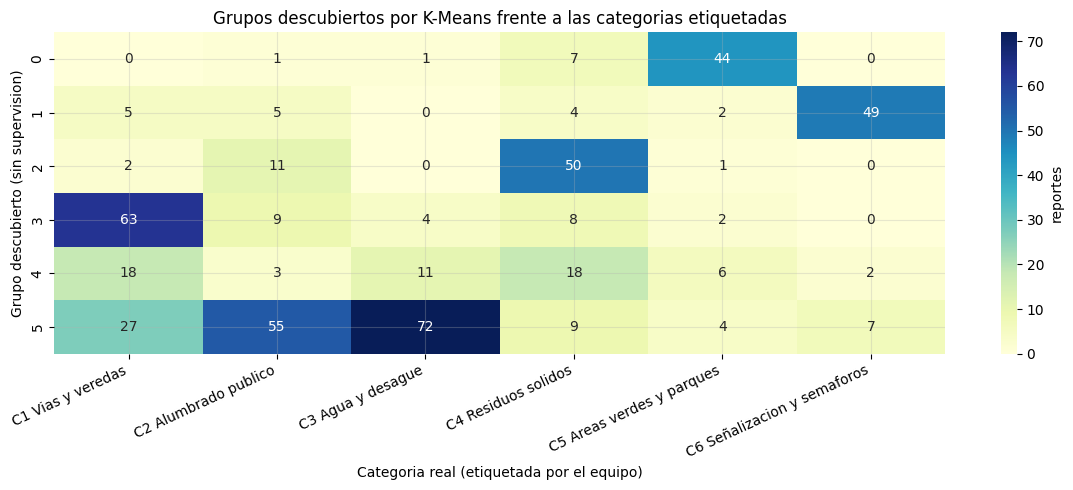

categoria,C1 Vias y veredas,C2 Alumbrado publico,C3 Agua y desague,C4 Residuos solidos,C5 Areas verdes y parques,C6 Señalizacion y semaforos
grupo,,,,,,
0,0,1,1,7,44,0
1,5,5,0,4,2,49
2,2,11,0,50,1,0
3,63,9,4,8,2,0
4,18,3,11,18,6,2
5,27,55,72,9,4,7


In [10]:
cruce = pd.crosstab(df.grupo, df.categoria)

plt.figure(figsize=(12, 5))
sns.heatmap(cruce, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "reportes"})
plt.title("Grupos descubiertos por K-Means frente a las categorias etiquetadas")
plt.xlabel("Categoria real (etiquetada por el equipo)")
plt.ylabel("Grupo descubierto (sin supervision)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()

cruce

In [11]:
print("CORRESPONDENCIA GRUPO -> CATEGORIA\n" + "=" * 78)
purezas = []
for g in range(6):
    fila = cruce.loc[g]
    dominante, n = fila.idxmax(), fila.max()
    pureza = 100 * n / fila.sum()
    purezas.append(pureza)
    print(f"Grupo {g}: {dominante:<28} {n:>3}/{fila.sum():<4} pureza = {pureza:.0f}%")

print(f"\nPureza media: {np.mean(purezas):.1f}%   (primer intento: {pureza_1:.0f}%)")
print(f"Indice Rand ajustado: {ari:.3f}")
print("   0 = coincidencia puramente casual | 1 = coincidencia perfecta")

CORRESPONDENCIA GRUPO -> CATEGORIA
Grupo 0: C5 Areas verdes y parques     44/53   pureza = 83%
Grupo 1: C6 Señalizacion y semaforos   49/65   pureza = 75%
Grupo 2: C4 Residuos solidos           50/64   pureza = 78%
Grupo 3: C1 Vias y veredas             63/86   pureza = 73%
Grupo 4: C1 Vias y veredas             18/58   pureza = 31%
Grupo 5: C3 Agua y desague             72/174  pureza = 41%

Pureza media: 63.7%   (primer intento: 26%)
Indice Rand ajustado: 0.300
   0 = coincidencia puramente casual | 1 = coincidencia perfecta


**Cómo se lee el ARI.** El índice Rand ajustado compara dos formas de partir el mismo conjunto, corrigiendo por la coincidencia que se daría al azar. Un valor claramente por encima de cero significa que el algoritmo, sin haber visto una sola etiqueta, llegó a una organización emparentada con la que el equipo construyó a mano.

No llega a 1 ni podría: K-Means reparte por parecido léxico y no sabe nada de gerencias municipales. Lo relevante es que la mejora respecto del primer intento es grande, y que los grupos más puros corresponden a las categorías con vocabulario más propio.

### 4.1. Visualización en dos dimensiones

Los reportes viven en un espacio de cientos de dimensiones, imposible de dibujar. Se proyecta a dos componentes para ver la forma general. Es una simplificación fuerte: sirve para mirar, no para concluir.

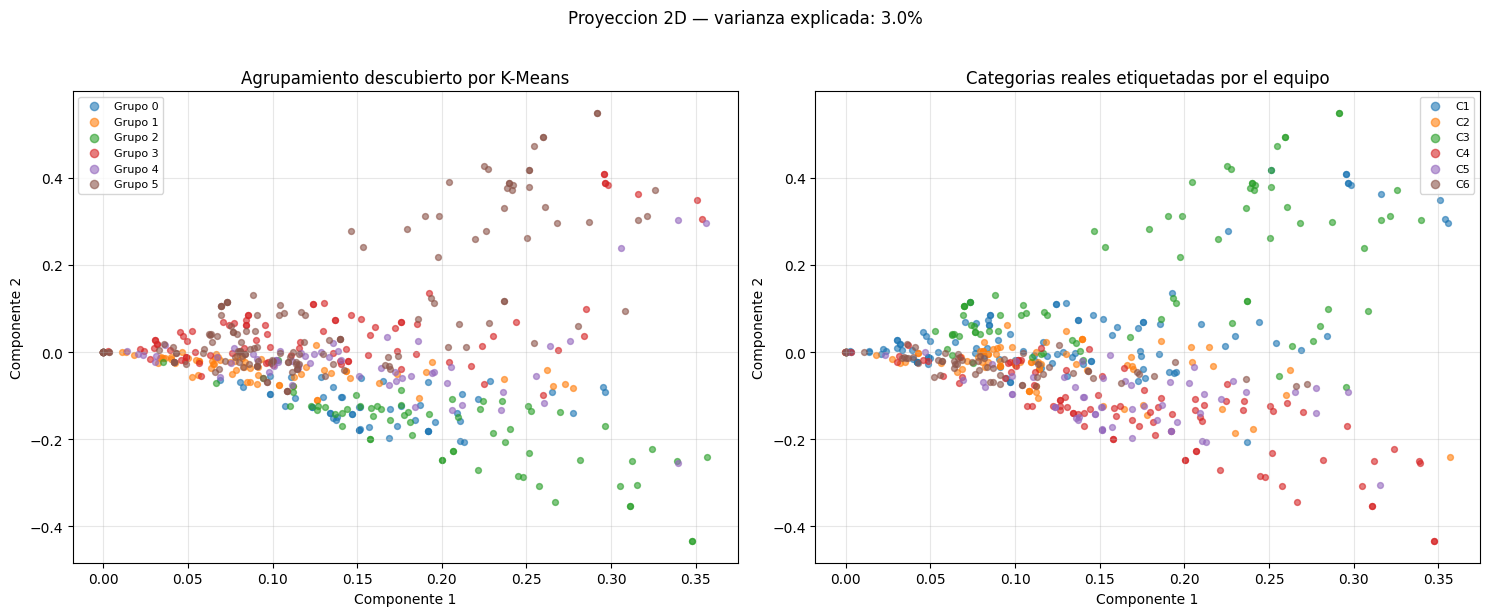

In [12]:
svd2 = TruncatedSVD(n_components=2, random_state=SEMILLA)
coords = svd2.fit_transform(X)

fig, ejes = plt.subplots(1, 2, figsize=(15, 6))

for g in range(6):
    m = df.grupo == g
    ejes[0].scatter(coords[m, 0], coords[m, 1], s=18, alpha=0.6, label=f"Grupo {g}")
ejes[0].set_title("Agrupamiento descubierto por K-Means")
ejes[0].legend(fontsize=8, markerscale=1.4)

for cat in sorted(df.categoria.unique()):
    m = df.categoria == cat
    ejes[1].scatter(coords[m, 0], coords[m, 1], s=18, alpha=0.6, label=cat[:2])
ejes[1].set_title("Categorias reales etiquetadas por el equipo")
ejes[1].legend(fontsize=8, markerscale=1.4)

for e in ejes:
    e.set_xlabel("Componente 1"); e.set_ylabel("Componente 2")

plt.suptitle(f"Proyeccion 2D — varianza explicada: "
             f"{100*svd2.explained_variance_ratio_.sum():.1f}%", y=1.02)
plt.tight_layout(); plt.show()

---
## 5. Mejora por aprendizaje nuevo: el grupo como variable del clasificador

Hasta aquí el agrupamiento sirvió como análisis. Ahora se lo pone a trabajar: se agrega el grupo descubierto como una variable más del clasificador de categoría del notebook principal, y se mide con validación cruzada si aporta algo.

In [13]:
from scipy.sparse import hstack, csr_matrix

vec_sup = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_sup = vec_sup.fit_transform(df.texto_limpio)
grupo_oh = pd.get_dummies(df.grupo, prefix="g").values.astype(float)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
modelo = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA)

f1_base = cross_val_score(modelo, X_sup, df.categoria, cv=cv, scoring="f1_macro")

# Una variable indicadora vale 1, mientras que un peso TF-IDF tipico vale ~0.2.
# Si se la agrega tal cual, esa sola columna pesa mas que varias palabras juntas.
# Se barre un factor de escala para separar el efecto de la informacion
# del efecto de la magnitud.
pesos, medias, desvs = [], [], []
for w in [1.0, 0.5, 0.3, 0.1, 0.05]:
    X_amp = hstack([X_sup, csr_matrix(grupo_oh * w)]).tocsr()
    s = cross_val_score(modelo, X_amp, df.categoria, cv=cv, scoring="f1_macro")
    pesos.append(w); medias.append(s.mean()); desvs.append(s.std())

print("Clasificacion de categoria — validacion cruzada de 5 particiones")
print("=" * 70)
print(f"{'Solo TF-IDF (base)':<28} F1 macro = {f1_base.mean():.3f} (+/- {f1_base.std():.3f})")
for w, m, d in zip(pesos, medias, desvs):
    print(f"{'+ grupo, peso ' + str(w):<28} F1 macro = {m:.3f} (+/- {d:.3f})   "
          f"{m - f1_base.mean():+.3f}")

Clasificacion de categoria — validacion cruzada de 5 particiones
Solo TF-IDF (base)           F1 macro = 0.883 (+/- 0.037)
+ grupo, peso 1.0            F1 macro = 0.747 (+/- 0.046)   -0.136
+ grupo, peso 0.5            F1 macro = 0.757 (+/- 0.049)   -0.126
+ grupo, peso 0.3            F1 macro = 0.806 (+/- 0.037)   -0.077
+ grupo, peso 0.1            F1 macro = 0.878 (+/- 0.031)   -0.005
+ grupo, peso 0.05           F1 macro = 0.880 (+/- 0.033)   -0.003


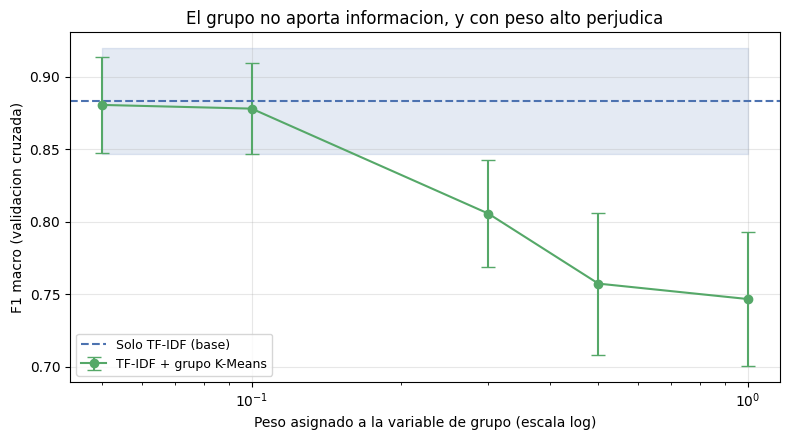

In [14]:
plt.figure(figsize=(8, 4.5))
plt.errorbar(pesos, medias, yerr=desvs, fmt="o-", capsize=5, color="#55A868",
             label="TF-IDF + grupo K-Means")
plt.axhline(f1_base.mean(), color="#4C72B0", linestyle="--", label="Solo TF-IDF (base)")
plt.fill_between([min(pesos), max(pesos)],
                 f1_base.mean() - f1_base.std(), f1_base.mean() + f1_base.std(),
                 color="#4C72B0", alpha=0.15)
plt.xscale("log"); plt.xlabel("Peso asignado a la variable de grupo (escala log)")
plt.ylabel("F1 macro (validacion cruzada)")
plt.title("El grupo no aporta informacion, y con peso alto perjudica")
plt.legend(fontsize=9); plt.tight_layout(); plt.show()

**El resultado es negativo, y está bien diagnosticado.** El grupo no mejora la clasificación con ningún peso: a medida que el peso baja, el desempeño simplemente vuelve al de la base. Eso descarta que el problema fuera de escala y deja la explicación de fondo: el grupo se calculó a partir del mismo texto que ya usa el clasificador, de modo que no aporta información nueva, solo la misma información resumida y con las pérdidas propias del resumen.

Lo que sí se aprende del barrido es un principio general de ingeniería de características: **una variable indicadora agregada a una matriz TF-IDF entra con una magnitud mucho mayor que cualquier palabra**, y si no se la escala termina dominando la decisión del modelo. Con peso 1 la caída es grande; con peso 0,05 desaparece.

Reportar esto tal como salió es parte del trabajo. Un experimento que no mejora el resultado sigue siendo válido si está bien medido; lo contrario —probar variantes hasta que una dé mejor y reportar solo esa— es lo que invalida un diseño experimental.

---
## 6. Aplicación práctica: perfil temático por zona

Un segundo uso del agrupamiento, este sí directamente accionable para la municipalidad: cruzar los grupos temáticos con las zonas de la ciudad para ver qué tipo de problema predomina en cada una.

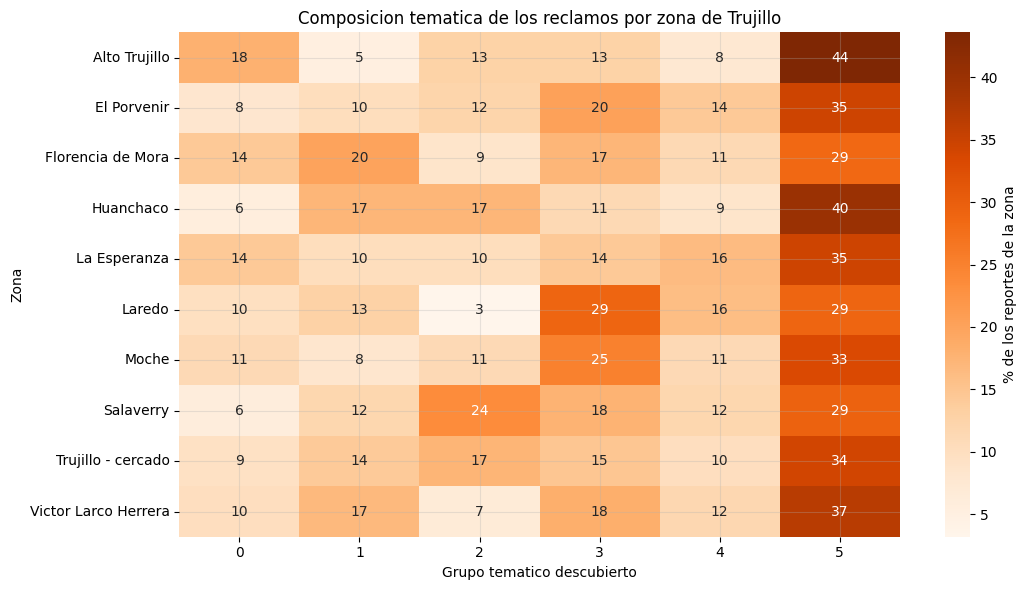

Grupo tematico dominante por zona:
   Alto Trujillo            grupo 5  (44% de sus reportes)
   El Porvenir              grupo 5  (35% de sus reportes)
   Florencia de Mora        grupo 5  (29% de sus reportes)
   Huanchaco                grupo 5  (40% de sus reportes)
   La Esperanza             grupo 5  (35% de sus reportes)
   Laredo                   grupo 3  (29% de sus reportes)
   Moche                    grupo 5  (33% de sus reportes)
   Salaverry                grupo 5  (29% de sus reportes)
   Trujillo - cercado       grupo 5  (34% de sus reportes)
   Victor Larco Herrera     grupo 5  (37% de sus reportes)


In [15]:
grupo_zona = pd.crosstab(df.zona, df.grupo, normalize="index") * 100

plt.figure(figsize=(11, 6))
sns.heatmap(grupo_zona.round(1), annot=True, fmt=".0f", cmap="Oranges",
            cbar_kws={"label": "% de los reportes de la zona"})
plt.title("Composicion tematica de los reclamos por zona de Trujillo")
plt.xlabel("Grupo tematico descubierto"); plt.ylabel("Zona")
plt.tight_layout(); plt.show()

print("Grupo tematico dominante por zona:")
for zona in grupo_zona.index:
    g = grupo_zona.loc[zona].idxmax()
    print(f"   {zona:<24} grupo {g}  ({grupo_zona.loc[zona, g]:.0f}% de sus reportes)")

---
## 7. Conclusiones

In [16]:
print("RESUMEN DEL ANALISIS NO SUPERVISADO")
print("=" * 72)
print(f"Reportes agrupados            : {len(df)}")
print(f"Grupos solicitados            : 6 (para comparar con la taxonomia de la PC2)")
print("")
print(f"{'':<28}{'1er intento':>14}{'2do intento':>14}")
print(f"{'Coeficiente de silueta':<28}{silhouette_score(X_1, grupos_1):>14.3f}{silueta:>14.3f}")
print(f"{'Indice Rand ajustado':<28}{ari_1:>14.3f}{ari:>14.3f}")
print(f"{'Pureza media de los grupos':<28}{pureza_1:>13.0f}%{np.mean(purezas):>13.0f}%")
print("")
mejor_w = medias.index(max(medias))
print(f"Clasificador solo con TF-IDF           : F1 macro = {f1_base.mean():.3f}")
print(f"Mejor variante con el grupo agregado   : F1 macro = {max(medias):.3f} "
      f"(peso {pesos[mejor_w]})")
print(f"Aporte del agrupamiento al clasificador: "
      f"{max(medias) - f1_base.mean():+.3f} de F1 macro")

RESUMEN DEL ANALISIS NO SUPERVISADO
Reportes agrupados            : 500
Grupos solicitados            : 6 (para comparar con la taxonomia de la PC2)

                               1er intento   2do intento
Coeficiente de silueta               0.022         0.284
Indice Rand ajustado                 0.014         0.300
Pureza media de los grupos             26%           64%

Clasificador solo con TF-IDF           : F1 macro = 0.883
Mejor variante con el grupo agregado   : F1 macro = 0.880 (peso 0.05)
Aporte del agrupamiento al clasificador: -0.003 de F1 macro


1. **El preprocesamiento decidió el resultado, no el algoritmo.** Se usó el mismo K-Means en los dos intentos. La diferencia entre un agrupamiento inservible y uno interpretable estuvo enteramente en qué palabras se dejaron entrar y en la reducción de dimensionalidad. En procesamiento de lenguaje natural con corpus pequeños, esa es la lección práctica más transferible del ejercicio.

2. **Lo más repetido no es lo más informativo.** Las fórmulas de cortesía y de queja dominaban la señal porque se repiten en todos los reportes sin importar el tema. Detectarlas y tratarlas como palabras vacías de dominio es un paso que no aparece en los tutoriales, donde los corpus ya vienen limpios.

3. **La taxonomía de seis categorías tiene respaldo en los datos.** Tras la corrección, K-Means reconstruyó sin ver una sola etiqueta una organización emparentada con las seis áreas de servicio que el equipo derivó de la estructura de gerencias de la municipalidad.

4. **Las fronteras borrosas son las mismas en ambos enfoques.** Los grupos menos puros corresponden a las categorías que el clasificador supervisado también confundía en el notebook principal. Que dos técnicas independientes fallen en el mismo punto indica que el problema está en el solapamiento real del vocabulario, no en el algoritmo.

5. **El valor del agrupamiento no está en la métrica.** Está en dos usos operativos: abaratar el etiquetado de futuras tandas de reportes revisando por grupo en lugar de uno por uno, y perfilar qué problema predomina en cada zona de la ciudad, información directamente útil para las gerencias.

### Limitación

El corpus es de elaboración propia. Los grupos que emergen reflejan en parte la estructura con que el equipo redactó los reportes — de hecho, el primer intento agrupó precisamente por esas muletillas de redacción. Sobre un corpus recolectado de canales reales el agrupamiento sería más ruidoso y probablemente aparecerían grupos ajenos a la taxonomía prevista, que es el escenario donde esta técnica resulta más reveladora.